# TP4 — Intenções bancárias com BANKING77

Fintech Guard | Integrante A — Dados e IA | Experimento `tp4-banking77-v1`

**Pergunta:** qual solicitação bancária uma mensagem de atendimento expressa, entre as 77
intenções BANKING77? O agente combinará esse resultado com a análise de segurança já
desenvolvida, preservando a proposta original de duas funções complementares.

Este notebook é a evidência principal de classificação de intenções do TP4. O notebook de
`security/` continua ativo e separado, pois os rótulos não têm o mesmo significado.
Conteúdo de ameaça não comprova intenção maliciosa do cliente que relata um golpe.
O [adendo de arquitetura](../../../reports/TP4/arquitetura_dupla.md) registra a retomada,
sem reescrever os documentos históricos do TP3.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"scripts/tp4_banking77.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from scripts.tp4_banking77 import prepare, train_models, evaluate, GRID, SEED
OUT=ROOT/"reports/TP4/banking77"
FIG=ROOT/"reports/TP4/figures/banking77"
FIG.mkdir(parents=True,exist_ok=True)
sns.set_theme(style="whitegrid")
print("Ambiente e caminhos relativos preparados.")

Ambiente e caminhos relativos preparados.


## 1. Origem, classes e auditoria anterior ao treino

BANKING77, PolyAI: originalmente 10.003 mensagens de treino e 3.080 de teste, com 77
intenções em inglês. Licença CC BY 4.0; ver [origem e citação](https://github.com/PolyAI-LDN/task-specific-datasets#banking).
A limpeza do TP1 deixou 9.993/3.079. Seus arquivos permanecem preservados.

A auditoria TP4 encontrou uma sobreposição adicional por normalização exata mais rigorosa.
A preparação amplia a verificação para templates e similares: NFKC, casefold, espaços,
URLs/emails/números substituídos apenas para comparação; templates iguais ou Jaccard ≥0,90
de conjuntos de 5-gramas de caracteres, ambos os textos com ≥40 caracteres. Componentes
conexos inteiros são respeitados. A busca por prefixos ordenados por frequência apenas
acelera candidatos; a similaridade é calculada exatamente nos conjuntos completos.

O agrupamento não usa rótulos nem scores de modelo. Toda linha de treino em um componente
com algum texto de teste é excluída do **novo treino TP4**, com IDs/hashes e motivo registrados.
O teste de 3.079 linhas é preservado. Textos mantidos não são traduzidos ou reescritos.
Isso reduz sobreposição detectável, sem demonstrar independência por autor/origem.

In [2]:
train,test,cv,labels=prepare(ROOT)
audit=json.loads((OUT/"data_audit.json").read_text(encoding="utf-8"))
display(pd.Series(audit,name="resultado").to_frame())
display(train[["text","category"]].dtypes.to_frame("tipo"))
display(train[["text","category"]].isna().sum().to_frame("ausentes"))
display(train.assign(n_characters=train.text.str.len())[["category","n_characters"]].describe(include="all"))
distribution=pd.read_csv(OUT/"class_distribution.csv",index_col=0)
with pd.option_context("display.max_rows",None): display(distribution)
print("Exclusões rastreáveis:",len(pd.read_csv(OUT/"excluded_training_rows.csv")))
print("Classes nos folds de validação:",[train.iloc[val].category.nunique() for _,val in cv])

Exclusões rastreáveis: 8
Classes nos folds de validação: [77, 77, 77, 77, 77]


,resultado
source_train_rows,9993
test_rows,3079
retained_train_rows,9985
excluded_train_rows,8
classes,77
groups,13047
multirow_groups,22
largest_group,3
similar_pairs,25
mixed_label_groups_total,0


,tipo
text,object
category,object


,ausentes
text,0
category,0


,category,n_characters
count,9985,9985.000000
unique,77,NaN
top,card_payment_fee_charged,NaN
freq,187,NaN
mean,NaN,59.432949
std,NaN,40.800289
min,NaN,13.000000
25%,NaN,36.000000
50%,NaN,47.000000
75%,NaN,64.000000


,excluded_test_overlap,test,train
category,,,
Refund_not_showing_up,0,40,162
activate_my_card,0,40,159
age_limit,0,40,110
apple_pay_or_google_pay,0,40,126
atm_support,0,39,85
automatic_top_up,0,40,127
balance_not_updated_after_bank_transfer,0,40,171
balance_not_updated_after_cheque_or_cash_deposit,0,40,181
beneficiary_not_allowed,0,40,156


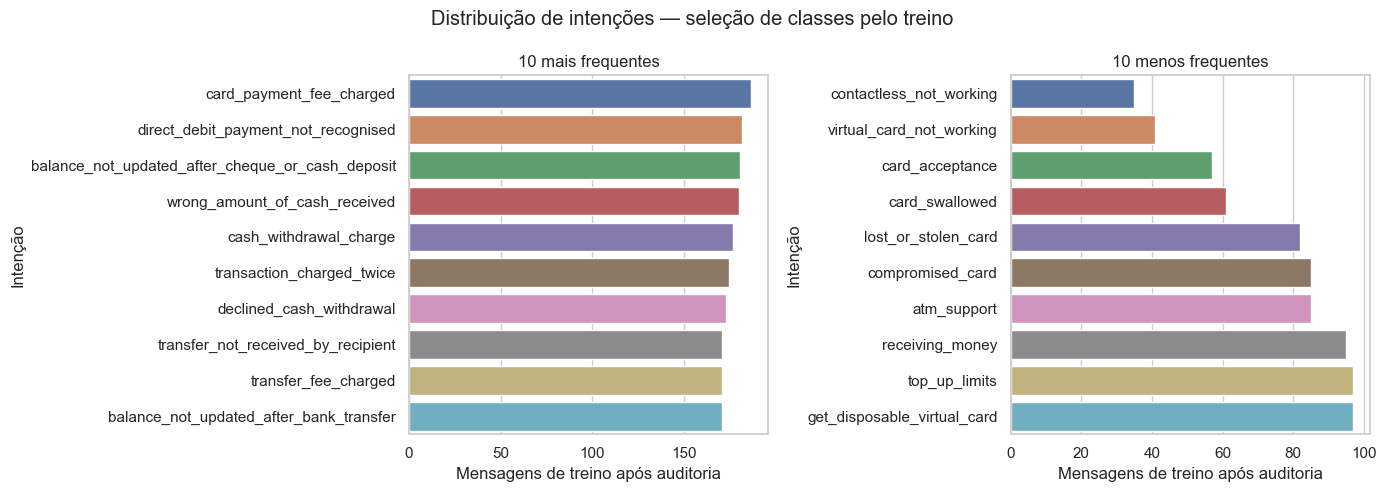

In [3]:
counts=train.category.value_counts()
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,part,title in [(axes[0],counts.head(10),"10 mais frequentes"),(axes[1],counts.tail(10).sort_values(),"10 menos frequentes")]:
    sns.barplot(x=part.values,y=part.index,hue=part.index,legend=False,ax=ax)
    ax.set(title=title,xlabel="Mensagens de treino após auditoria",ylabel="Intenção")
fig.suptitle("Distribuição de intenções — seleção de classes pelo treino")
fig.tight_layout();fig.savefig(FIG/"distribuicao.png",dpi=150);plt.show()

A distribuição do treino não é uniforme. Macro-F1 dá o mesmo peso a cada intenção,
enquanto weighted-F1 depende do suporte. A figura mostra extremos selecionados no treino;
a tabela anterior contém as 77 classes. A qualidade precisa ser examinada por classe,
inclusive nas intenções com poucos exemplos.

## 2. Protocolo congelado e pipeline completo

Teste: split oficial já limpo no TP1, reservado à avaliação após a seleção. Treino/validação:
cinco folds `StratifiedGroupKFold`, seed 42; nenhum grupo cruza os folds e todas as 77
classes estão presentes em cada treino/validação. O protocolo e o manifesto são gravados
antes das métricas; alterações posteriores de partição/parâmetros exigem novo experimento.
O teste já passou pela EDA: é benchmark do domínio, não validação externa intocada.

Pipeline: TF-IDF de palavras → LogisticRegression multiclasse com L2, solver lbfgs.
Em scikit-learn 1.9, esse solver usa a perda multinomial para mais de duas classes.
Vocabulário/IDF são ajustados **dentro de cada fold**. Sem categorias, IDs, hashes, grupos
ou outra informação de rótulo como features. Preservei negações, sem lista de stopwords.
O modelo escolhe a maior probabilidade; não foi selecionado limiar de confiança no teste.

In [4]:
pipeline=Pipeline([
    ("tfidf",TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True,
                             max_features=30000,stop_words=None,lowercase=True)),
    ("classifier",LogisticRegression(C=1.0,solver="lbfgs",max_iter=1000,random_state=SEED)),
])
display(pipeline)
display(GRID)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",30000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


{'classifier__C': [0.1, 1.0, 10.0],
 'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)]}

## 3. Baseline, configuração inicial e GridSearchCV

Baseline: DummyClassifier(strategy="prior"), que prevê a maioria e retorna scores constantes.
Inicial: C=1 e unigramas/bigramas. Grade: **C ∈ {0,1;1;10}** e
**ngram_range ∈ {(1,1);(1,2);(1,3)}**, total 9 candidatos × 5 folds = 45 ajustes + refit.
Os dois parâmetros têm três valores. A escolha usa somente macro-F1 médio dos folds.

`train_models` executa essa busca com `GridSearchCV`, comparação das referências nos mesmos
folds e refit dos modelos no treino. O código está em `scripts/tp4_banking77.py`; warnings
de convergência interrompem o experimento. Execução com um thread numérico evita saturação
do ambiente; isso não altera o critério de seleção.

In [5]:
models,scores,search=train_models(ROOT,train,cv,pipeline)
print("GridSearchCV executado:",type(search).__name__)
print("Candidatos:",len(search.cv_results_["params"]))
print("Melhores parâmetros:",search.best_params_)
print(f"Macro-F1 CV selecionado: {search.best_score_:.4f}")
cv_results=pd.read_csv(OUT/"cv_results.csv")
display(cv_results[["params","mean_test_score","std_test_score","rank_test_score"]].sort_values("rank_test_score"))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 1); total time=   0.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 1); total time=   0.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 1); total time=   0.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 1); total time=   0.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 1); total time=   0.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 2); total time=   1.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 2); total time=   1.6s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 2); total time=   1.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 2); total time=   1.6s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 2); total time=   1.5s
[CV] END .......classifier__C=0.1, tfidf__ngram_range=(1, 3); total time=   2.9s
[CV] END .......classifier__C=0.1, tfidf__ngram_r

,params,mean_test_score,std_test_score,rank_test_score
6,"{'classifier__C': 10.0, 'tfidf__ngram_range': ...",0.880668,0.004920,1
7,"{'classifier__C': 10.0, 'tfidf__ngram_range': ...",0.874552,0.005138,2
8,"{'classifier__C': 10.0, 'tfidf__ngram_range': ...",0.865388,0.007267,3
3,"{'classifier__C': 1.0, 'tfidf__ngram_range': (...",0.855525,0.007282,4
4,"{'classifier__C': 1.0, 'tfidf__ngram_range': (...",0.841538,0.005727,5
5,"{'classifier__C': 1.0, 'tfidf__ngram_range': (...",0.824654,0.007001,6
0,"{'classifier__C': 0.1, 'tfidf__ngram_range': (...",0.669734,0.006222,7
1,"{'classifier__C': 0.1, 'tfidf__ngram_range': (...",0.625700,0.005494,8
2,"{'classifier__C': 0.1, 'tfidf__ngram_range': (...",0.596497,0.007789,9


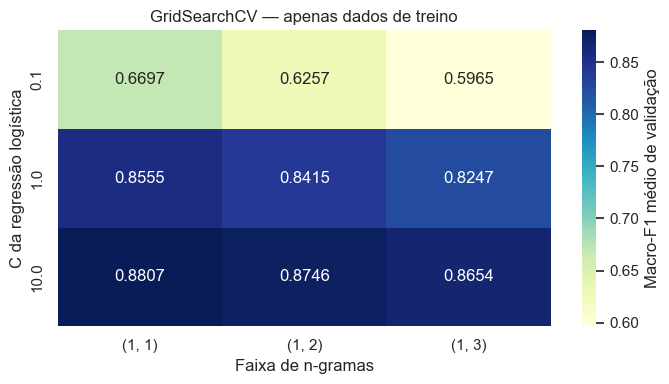

In [6]:
grid_table=pd.DataFrame(search.cv_results_)
grid_table["ngrams"]=grid_table.param_tfidf__ngram_range.map(str)
matrix=grid_table.pivot(index="param_classifier__C",columns="ngrams",values="mean_test_score")
fig,ax=plt.subplots(figsize=(7,4))
sns.heatmap(matrix,annot=True,fmt=".4f",cmap="YlGnBu",ax=ax,cbar_kws={"label":"Macro-F1 médio de validação"})
ax.set(title="GridSearchCV — apenas dados de treino",xlabel="Faixa de n-gramas",ylabel="C da regressão logística")
fig.tight_layout();fig.savefig(FIG/"grid.png",dpi=160);plt.show()

C maior reduz a regularização; n-gramas mais extensos representam expressões, mas podem
aumentar esparsidade. O mapa registra o que ocorreu na CV, sem presumir que mais complexidade
melhora o resultado. A média do vencedor é usada para seleção e pode ser otimista; o desvio
padrão entre folds não é intervalo de confiança. O teste ainda não foi usado para escolher.

## 4. Avaliação multiclasse no teste e comparação com baseline

As decisões estão fixadas. Os três modelos são avaliados no mesmo teste e não são reajustados
com suas linhas. ROC-AUC usa a matriz de probabilidades de 77 colunas na ordem de `classes_`,
com One-vs-Rest e média macro; também reportamos a média ponderada. Não se usa o rótulo
previsto como score de ROC. Cada classe é comparada às outras 76, portanto AUC alta pode
coexistir com confusão entre intenções próximas. A métrica principal continua macro-F1.

In [7]:
metrics,reports,predictions,probabilities=evaluate(ROOT,train,test,labels,models,scores,search)
display(metrics.round(4))
per_class=pd.read_csv(OUT/"per_class_tuned.csv")
with pd.option_context("display.max_rows",None): display(per_class.round(4))
indexed=metrics.set_index("model")
gain_cv=indexed.loc["tuned","cv_macro_f1_mean"]-indexed.loc["initial","cv_macro_f1_mean"]
gain_initial=indexed.loc["tuned","test_macro_f1"]-indexed.loc["initial","test_macro_f1"]
gain_baseline=indexed.loc["tuned","test_macro_f1"]-indexed.loc["majority","test_macro_f1"]
print(f"Macro-F1: ganho CV sobre inicial **{gain_cv:+.4f}**; ganho no teste sobre inicial "
                 f"**{gain_initial:+.4f}** e sobre baseline **{gain_baseline:+.4f}**. "
                 "A comparação permite avaliar aprendizado além da classe frequente neste corpus; "
                 "não comprova generalização para qualquer atendimento real. Ganho negativo também seria reportado.")

Macro-F1: ganho CV sobre inicial **+0.0391**; ganho no teste sobre inicial **+0.0409** e sobre baseline **+0.8998**. A comparação permite avaliar aprendizado além da classe frequente neste corpus; não comprova generalização para qualquer atendimento real. Ganho negativo também seria reportado.


,model,cv_macro_f1_mean,cv_macro_f1_std,test_accuracy,test_macro_f1,test_weighted_f1,test_balanced_accuracy,test_roc_auc_ovr_macro,test_roc_auc_ovr_weighted
0,majority,0.0005,0.0000,0.013,0.0003,0.0003,0.013,0.5000,0.5000
1,initial,0.8415,0.0057,0.860,0.8592,0.8592,0.860,0.9964,0.9964
2,tuned,0.8807,0.0049,0.900,0.9001,0.9001,0.900,0.9980,0.9980


,intent,precision,recall,f1-score,support,roc_auc_ovr
0,Refund_not_showing_up,0.9250,0.9250,0.9250,40.0,0.9997
1,activate_my_card,0.9744,0.9500,0.9620,40.0,0.9985
2,age_limit,1.0000,1.0000,1.0000,40.0,1.0000
3,apple_pay_or_google_pay,0.9756,1.0000,0.9877,40.0,1.0000
4,atm_support,0.9737,0.9487,0.9610,39.0,0.9997
5,automatic_top_up,1.0000,0.9000,0.9474,40.0,0.9999
6,balance_not_updated_after_bank_transfer,0.7073,0.7250,0.7160,40.0,0.9840
7,balance_not_updated_after_cheque_or_cash_deposit,0.9268,0.9500,0.9383,40.0,0.9997
8,beneficiary_not_allowed,0.9730,0.9000,0.9351,40.0,0.9998
9,cancel_transfer,0.9500,0.9500,0.9500,40.0,0.9999


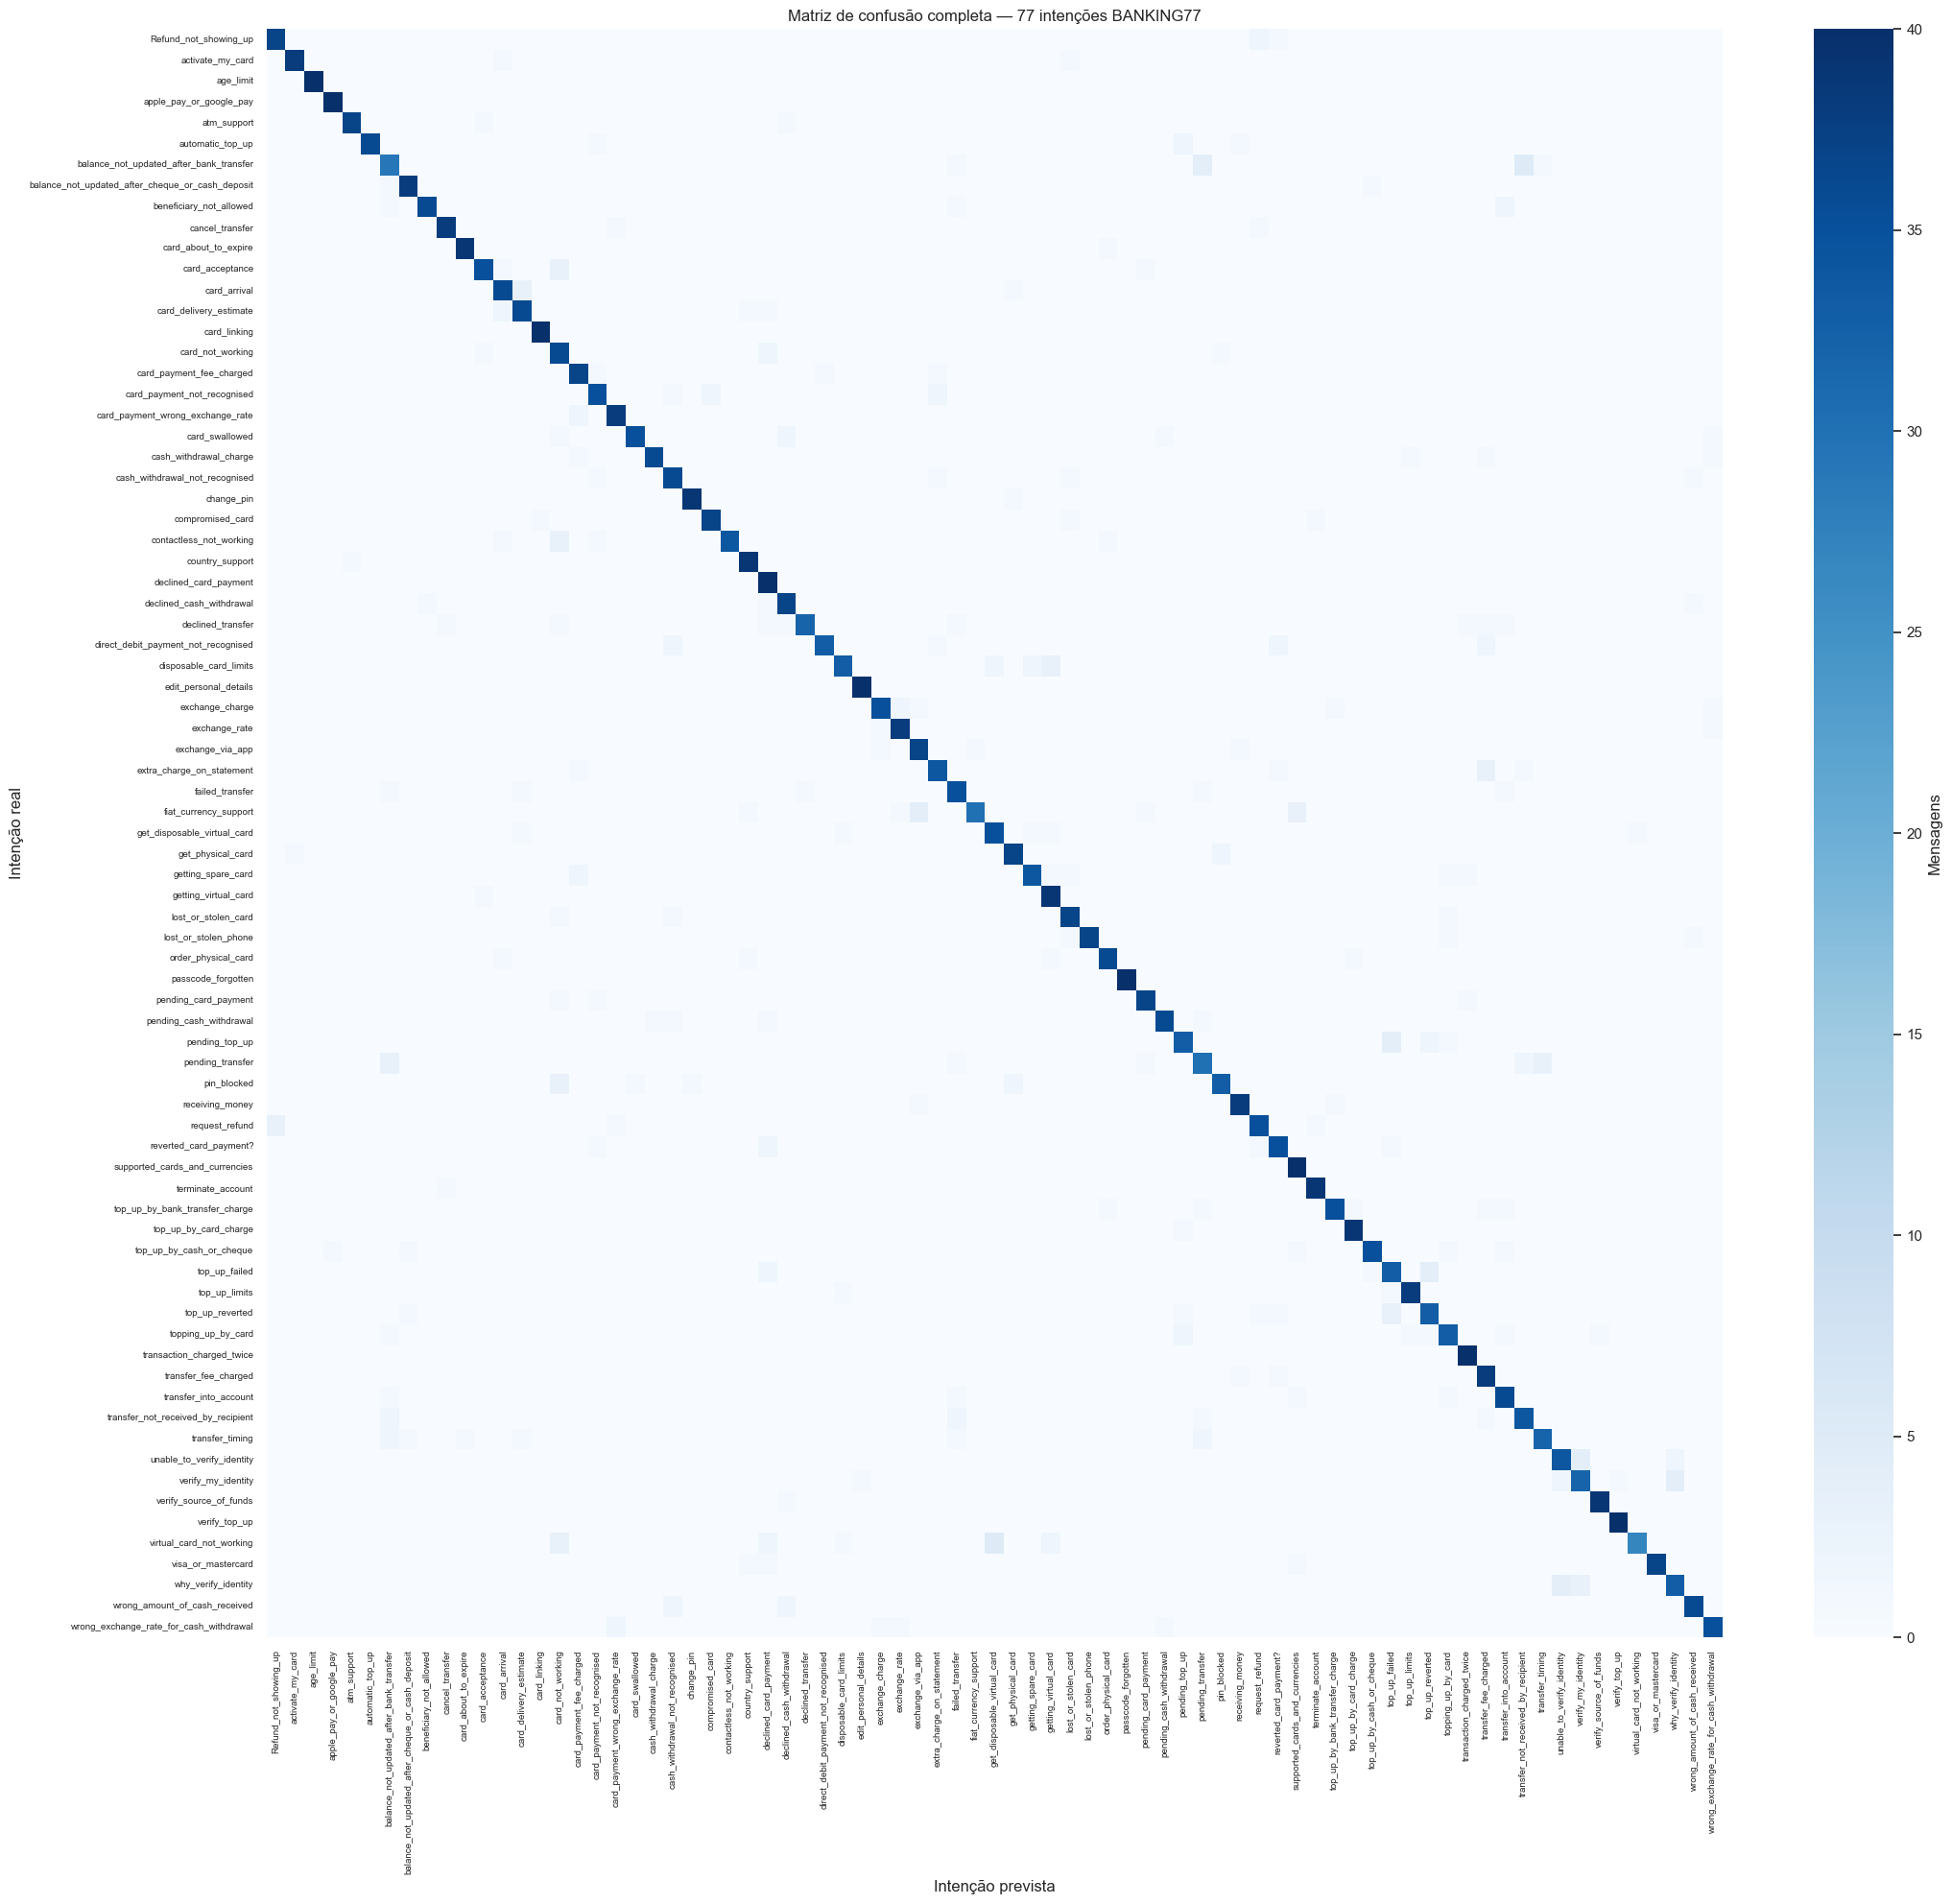

In [8]:
confusion=pd.read_csv(OUT/"confusion_tuned.csv",index_col=0)
fig,ax=plt.subplots(figsize=(22,20))
sns.heatmap(confusion,cmap="Blues",ax=ax,cbar_kws={"label":"Mensagens"})
ax.set(title="Matriz de confusão completa — 77 intenções BANKING77",xlabel="Intenção prevista",ylabel="Intenção real")
ax.tick_params(axis="both",labelsize=7)
fig.tight_layout();fig.savefig(FIG/"confusao_completa.png",dpi=150);plt.show()

A diagonal representa acertos; as demais células mostram erros de roteamento. A matriz
completa mantém todas as classes e está disponível em CSV e PNG ampliável. As figuras
seguintes resumem os erros para leitura; não substituem a matriz ou a tabela por classe.

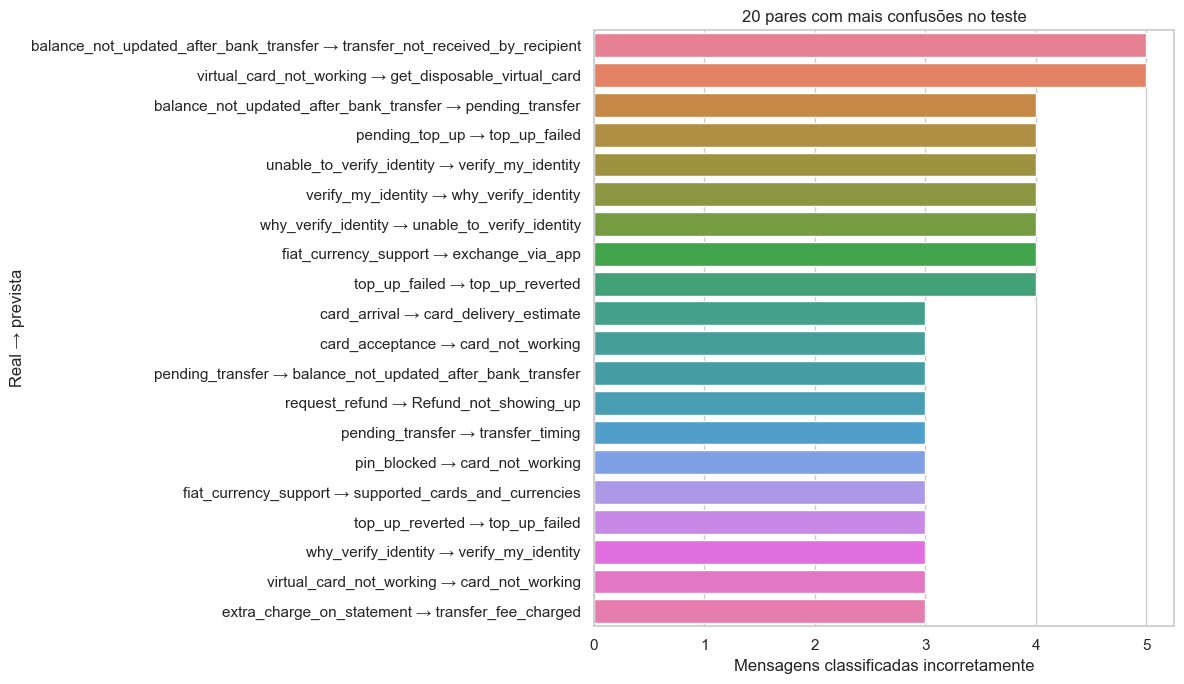

,actual,predicted,count
0,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,5
1,virtual_card_not_working,get_disposable_virtual_card,5
2,balance_not_updated_after_bank_transfer,pending_transfer,4
3,pending_top_up,top_up_failed,4
4,unable_to_verify_identity,verify_my_identity,4
5,verify_my_identity,why_verify_identity,4
6,why_verify_identity,unable_to_verify_identity,4
7,fiat_currency_support,exchange_via_app,4
8,top_up_failed,top_up_reverted,4
9,card_arrival,card_delivery_estimate,3


In [9]:
pairs=pd.read_csv(OUT/"confusion_pairs.csv").head(20).copy()
pairs["par"]=pairs.actual+" → "+pairs.predicted
fig,ax=plt.subplots(figsize=(12,7))
sns.barplot(data=pairs,x="count",y="par",hue="par",legend=False,ax=ax)
ax.set(title="20 pares com mais confusões no teste",xlabel="Mensagens classificadas incorretamente",ylabel="Real → prevista")
fig.tight_layout();fig.savefig(FIG/"maiores_confusoes.png",dpi=150);plt.show()
display(pairs[["actual","predicted","count"]])

Os pares acima identificam onde o modelo trocou uma intenção por outra. São diagnósticos posteriores à avaliação, sem alteração da grade, rótulos ou features. A proximidade semântica é uma hipótese para revisão futura, não uma causa comprovada só pela contagem.


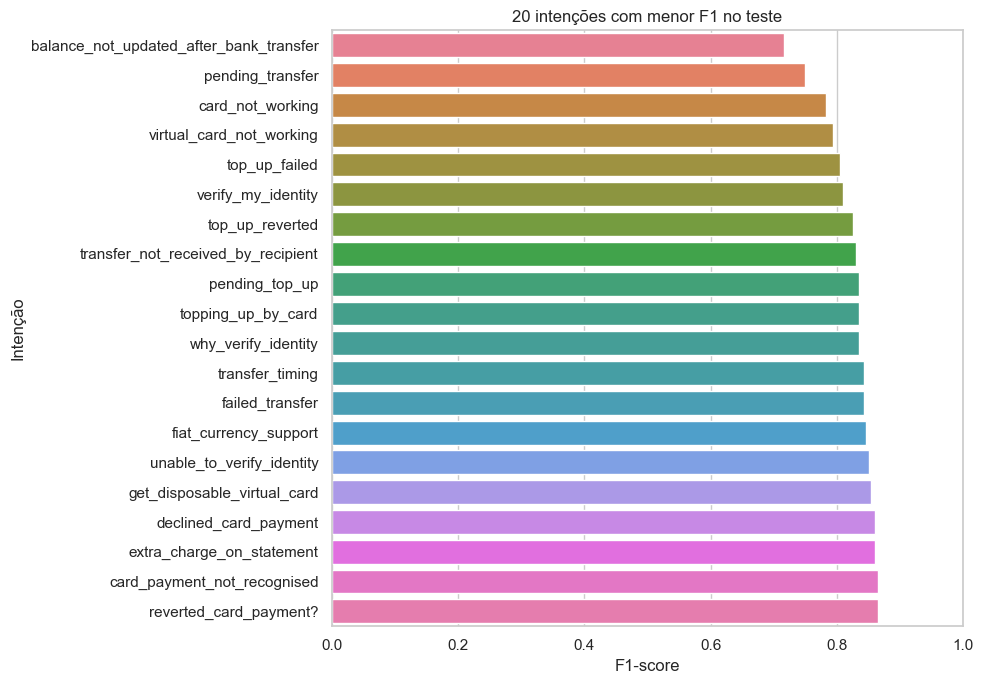

In [10]:
print("Os pares acima identificam onde o modelo trocou uma intenção por outra. "
                 "São diagnósticos posteriores à avaliação, sem alteração da grade, rótulos ou features. "
                 "A proximidade semântica é uma hipótese para revisão futura, não uma causa comprovada só pela contagem.")
worst=per_class.sort_values(["f1-score","intent"]).head(20)
fig,ax=plt.subplots(figsize=(10,7))
sns.barplot(data=worst,x="f1-score",y="intent",hue="intent",legend=False,ax=ax)
ax.set(title="20 intenções com menor F1 no teste",xlabel="F1-score",ylabel="Intenção",xlim=(0,1))
fig.tight_layout();fig.savefig(FIG/"f1_menores.png",dpi=150);plt.show()

F1 combina precisão e recall, mas pode esconder qual dos dois está baixo. A tabela de
77 classes permite investigar a direção dos erros. O recorte de menores F1 é descritivo e
não serve para descartar classes difíceis ou escolher novo modelo com este mesmo teste.

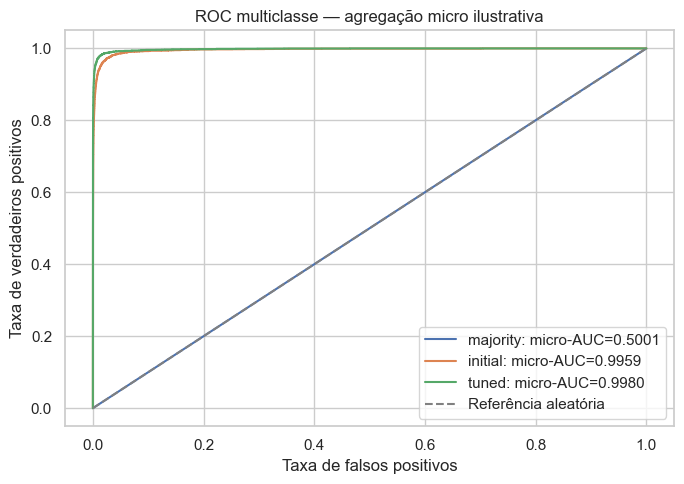

In [11]:
binary=label_binarize(test.category,classes=labels)
fig,ax=plt.subplots(figsize=(7,5))
for name in ["majority","initial","tuned"]:
    fpr,tpr,_=roc_curve(binary.ravel(),probabilities[name].ravel())
    ax.plot(fpr,tpr,label=f"{name}: micro-AUC={auc(fpr,tpr):.4f}")
ax.plot([0,1],[0,1],"--",color="gray",label="Referência aleatória")
ax.set(title="ROC multiclasse — agregação micro ilustrativa",xlabel="Taxa de falsos positivos",ylabel="Taxa de verdadeiros positivos")
ax.legend();fig.tight_layout();fig.savefig(FIG/"roc_micro.png",dpi=160);plt.show()

Esta figura usa agregação **micro** das decisões classe versus demais. As ROC-AUC **macro**
e ponderada exigidas na análise estão calculadas na tabela de métricas, e cada AUC OvR está
na tabela por classe. Micro e macro são agregações diferentes: a curva não deve ser rotulada
como macro. Com 77 classes, há muitos negativos em cada comparação; F1 por classe e confusões
continuam necessários para avaliar utilidade no atendimento.

## 5. Modelo serializado e composição com segurança

O artefato salvo contém TF-IDF e regressão logística ajustados somente nas linhas retidas
de treino. Metadados fixam classes originais, versões, hashes, protocolo e manifesto.
O wrapper valida versões e integridade; joblib só deve carregar artefatos revisados e confiáveis.

`ClassificationService` retorna intenção/probabilidade/versão bancária e um objeto `security`
com a saída do classificador de segurança. Os scores se referem a tarefas diferentes: não são
somados nem comparados como uma confiança única. Ambos recebem o mesmo texto integral.
O serviço não autentica nem cria rotas; B fará a ligação a `/classify` com JWT no startup.

In [12]:
from ml.banking_classifier import BankingClassifier
from ml.classification_service import ClassificationService
loaded=BankingClassifier(ROOT/"models/TP4/banking77")
check=predictions[predictions.model.eq("tuned")].set_index("test_row_id")
# Uma amostra determinística verifica recarga; os testes automatizados validam todas as previsões.
for _,row in test.iloc[:20].iterrows():
    result=loaded.classify(row.text)
    assert result["intent"]==check.loc[row.source_row_id,"predicted"]
    assert np.isclose(result["probability"],check.loc[row.source_row_id,"probability"])
service=ClassificationService(ROOT/"models/TP4/banking77",ROOT/"models/TP4/security")
# Exemplo sintético de inferência local, não conversa real de agente ou teste de qualidade.
display(service.classify("I lost my bank card. How can I report it?"))
print("Recarga conferida; inferência local composta disponível para integração.")

Recarga conferida; inferência local composta disponível para integração.


{'task': 'banking_intent_with_security',
 'intent': 'lost_or_stolen_card',
 'probability': 0.6843923187625798,
 'model_version': 'tp4-banking77-v1',
 'security': {'task': 'security_binary',
  'label': 'benign',
  'probability': 0.7692556740089183,
  'probabilities': {'benign': 0.7692556740089183,
   'threat': 0.2307443259910818},
  'model_version': 'tp4-security-binary-v1'}}

## 6. Limitações, agente e passagem ao integrante B

- BANKING77 é uma taxonomia fechada, em inglês. O modelo sempre retorna uma das 77 classes;
  não demonstrou detecção de assunto desconhecido, idioma diferente ou solicitação fora do escopo.
- A pergunta pode envolver múltiplas intenções, mas os dados e o modelo assumem um rótulo por
  mensagem. O agente deve pedir esclarecimentos sem solicitar dados sensíveis quando necessário.
- O teste pertence à mesma coleta e foi explorado na EDA. Similaridade heurística não assegura
  independência por autor; há um grupo de similares dentro do teste preservado. Probabilidades
  não foram calibradas; AUC elevada não demonstra segurança operacional.
- As categorias não cobrem automaticamente todo serviço bancário nem recomendações de investimento.
  Não se deve inventar classes nem tratar traduções como validação independente em português.
- O modelo de segurança continua com suas próprias limitações: 603 exemplos em inglês, licença
  não esclarecida e confusão possível entre relato legítimo e conteúdo ameaçador.
- Classificar conteúdo não autoriza transações, cancelamentos, bloqueios ou acusação do cliente.
  O agente usa os dois resultados como orientação e pode encaminhar para atendimento humano.
- O agente já tem código para consumir o contrato composto. A conversa real de três turnos
  depende de chave/modelo OpenAI e da rota integrada por B; testes simulados não cumprem essa evidência.

**Próximos passos:** integrar o serviço e schemas na API; validar JWT e erros HTTP; configurar
credenciais localmente; executar três turnos reais com intenções diferentes e revisar respostas;
obter avaliação externa bancária em português com condições de uso e anotação adequadas.

### Rastreabilidade e fontes

- [Notebook do componente de segurança](../security/01_classificacao.ipynb).
- [Protocolo congelado](../../../reports/TP4/banking77/protocol.json), [manifesto](../../../reports/TP4/banking77/split_manifest.csv).
- [Contrato para B](../../../reports/TP4/contrato_classify.md) e [alinhamento](../../../reports/TP4/alinhamento_francisco.md).
- [BANKING77 — fonte, licença e citação](https://github.com/PolyAI-LDN/task-specific-datasets#banking).
- [Regressão logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [ROC-AUC multiclasse](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

Reexecução idêntica reproduz o experimento já avaliado; não cria um novo teste independente.